# Домашнее задание 1

**Студент:** Пшеничников Глеб Викторович

**Датасет:** MTS Kion - https://github.com/irsafilo/KION_DATASET

UserKNN, iALS, EASE, факторизационная машина и iALS с собственным целевым сигналом.

Запуск: установить зависимости из `requirements.txt` и выполнить ноутбук сверху вниз. Архив с данными скачивается в `data/` при первом запуске.

In [1]:
import urllib.request
import zipfile
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import scipy.sparse as sp
import seaborn as sns
import torch

import utils
from models.ease import EASE
from models.fm import FactorizationMachine
from models.ials import ImplicitALS
from models.ials_custom import EngagementALS
from models.user_knn import UserKNN

SEED = 2021
np.random.seed(SEED)
torch.manual_seed(SEED)
sns.set_theme(style="whitegrid", palette="muted")
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(60)

DATA = Path("data")
URL = "https://github.com/irsafilo/KION_DATASET/raw/main/data_original.zip"

## 1. Данные

MTS Kion Implicit Contextualised Sequential Dataset - просмотры в онлайн-кинотеатре Kion с 13 марта по 22 августа 2021 года. Датасет выложен МТС к соревнованию ODS; ID анонимизированы, в данные добавлен шум. Берем полный архив `data_original.zip` из (https://github.com/irsafilo/KION_DATASET), ячейка ниже скачивает его в `data/`. В архиве три таблицы:

- `interactions` - одна строка на пару пользователь–контент: дата последнего просмотра `last_watch_dt`, суммарное время просмотра `total_dur` (секунды) и доля просмотренного `watched_pct` (%);
- `users` - анкета: возраст, доход, пол, есть ли дети;
- `items` - тип (фильм или сериал), название, год, жанры, страны, возрастной рейтинг, пометка «для детей», студии, режиссёры, актёры, описание, ключевые слова.

Взаимодействие - неявный отклик: пользователь открыл фильм или сериал и смотрел его какое-то время. Явных оценок нет.

In [2]:
DATA.mkdir(exist_ok=True)
archive = DATA / "data_original.zip"
if not archive.exists():
    urllib.request.urlretrieve(URL, archive)
with zipfile.ZipFile(archive) as z:
    for name in ("interactions", "users", "items"):
        target = DATA / f"{name}.csv"
        if not target.exists():
            target.write_bytes(z.read(f"data_original/{name}.csv"))

interactions = pl.read_csv(DATA / "interactions.csv", try_parse_dates=True)
users = pl.read_csv(DATA / "users.csv")
items = pl.read_csv(DATA / "items.csv")
interactions.head()

user_id,item_id,last_watch_dt,total_dur,watched_pct
i64,i64,date,i64,f64
176549,9506,2021-05-11,4250,72.0
699317,1659,2021-05-29,8317,100.0
656683,7107,2021-05-09,10,0.0
864613,7638,2021-07-05,14483,100.0
964868,9506,2021-04-30,6725,100.0


In [3]:
pl.DataFrame({
    "взаимодействий": [interactions.height],
    "пользователей": [interactions["user_id"].n_unique()],
    "анкет": [users.height],
    "объектов": [interactions["item_id"].n_unique()],
    "в каталоге": [items.height],
    "первый день": [interactions["last_watch_dt"].min()],
    "последний день": [interactions["last_watch_dt"].max()],
})

взаимодействий,пользователей,анкет,объектов,в каталоге,первый день,последний день
i64,i64,i64,i64,i64,date,date
5476251,962179,840197,15706,15963,2021-03-13,2021-08-22


**Объём.** Исходно 5,48 млн взаимодействий, 962 тыс. пользователей и 15,7 тыс. объектов.

**Что рекомендуем.** Каждому пользователю - 10 фильмов и сериалов, которые он ещё не открывал.

**Что релевантно.** Сам факт открытия говорит мало: многие просмотры обрываются через минуту. Релевантным считаю контент, который пользователь действительно посмотрел: досмотрел хотя бы до половины (`watched_pct ≥ 50`) или смотрел не меньше 20 минут (`total_dur ≥ 1200`). Второе условие нужно для сериалов: процент у них считается от всего сериала и почти всегда мал. Критерий один для всех моделей.

## 2. EDA и подготовка

In [4]:
def null_shares(name, frame):
    return (frame.null_count()
            .transpose(include_header=True, header_name="поле", column_names=["доля пропусков"])
            .with_columns(pl.col("доля пропусков") / frame.height)
            .filter(pl.col("доля пропусков") > 0)
            .select(pl.lit(name).alias("таблица"), pl.all()))


pl.concat([null_shares(name, frame) for name, frame in
           (("interactions", interactions), ("users", users), ("items", items))])

таблица,поле,доля пропусков
str,str,f64
"""interactions""","""watched_pct""",0.000151
"""users""","""age""",0.016776
"""users""","""income""",0.017586
"""users""","""sex""",0.016462
"""items""","""title_orig""",0.29725
"""items""","""release_year""",0.006139
"""items""","""countries""",0.002318
"""items""","""for_kids""",0.964543
"""items""","""age_rating""",0.000125


In [5]:
pl.DataFrame({
    "": ["полных дубликатов", "повторов пары пользователь–объект", "пользователей без анкеты",
         "объектов без карточки в каталоге"],
    "число": [interactions.is_duplicated().sum(),
              interactions.select("user_id", "item_id").is_duplicated().sum(),
              interactions.join(users, on="user_id", how="anti")["user_id"].n_unique(),
              interactions.join(items, on="item_id", how="anti")["item_id"].n_unique()],
})

,число
str,i64
"""полных дубликатов""",0
"""повторов пары пользователь–объект""",0
"""пользователей без анкеты""",217891
"""объектов без карточки в каталоге""",0


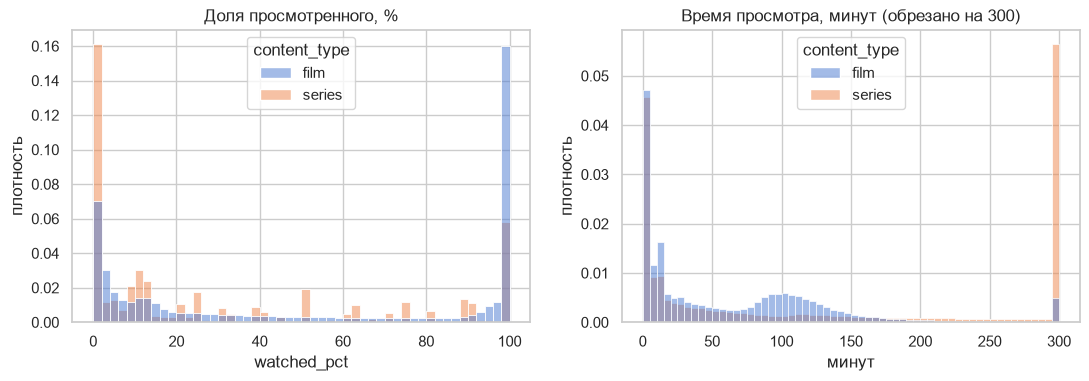

content_type,просмотров,медиана %,медиана минут,короче минуты,релевантных
str,u32,f64,f64,f64,f64
"""film""",4137134,45.0,41.733333,0.11713,0.605789
"""series""",1339117,13.0,80.116667,0.129688,0.659954


In [6]:
watch = interactions.join(items.select("item_id", "content_type"), on="item_id").with_columns(
    (pl.col("total_dur") / 60).clip(upper_bound=300).alias("минут"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.histplot(watch.select("watched_pct", "content_type").to_pandas(), x="watched_pct", hue="content_type",
             bins=50, stat="density", common_norm=False, ax=axes[0])
sns.histplot(watch.select("минут", "content_type").to_pandas(), x="минут", hue="content_type",
             bins=60, stat="density", common_norm=False, ax=axes[1])
axes[0].set(title="Доля просмотренного, %", ylabel="плотность")
axes[1].set(title="Время просмотра, минут (обрезано на 300)", ylabel="плотность")
plt.show()

watch.group_by("content_type").agg(
    pl.len().alias("просмотров"),
    pl.col("watched_pct").median().alias("медиана %"),
    (pl.col("total_dur") / 60).median().alias("медиана минут"),
    (pl.col("total_dur") < 60).mean().alias("короче минуты"),
    ((pl.col("watched_pct") >= 50) | (pl.col("total_dur") >= 1200)).mean().alias("релевантных"),
).sort("content_type")

Фильмы досматривают чаще: медиана досмотра 45 % против 13 % у сериалов. Но у сериалов процент считается от всего сериала, а по времени их смотрят дольше: медиана 80 минут против 42. Около 12 % просмотров короче минуты. По выбранному критерию релевантны 61 % просмотров фильмов и 66 % - сериалов.

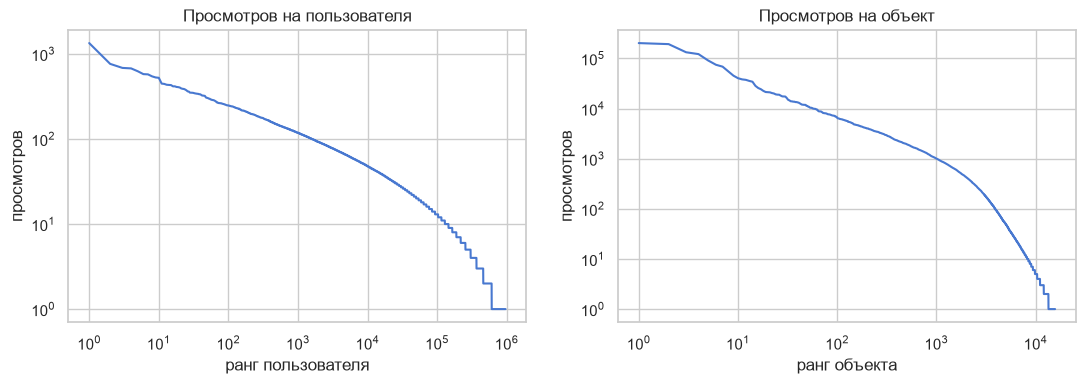

,на пользователя,на объект
str,f64,f64
"""count""",962179.0,15706.0
"""null_count""",0.0,0.0
"""mean""",5.69151,348.672546
"""std""",10.886262,3194.05358
"""min""",1.0,1.0
"""25%""",1.0,3.0
"""50%""",2.0,12.0
"""75%""",6.0,99.0
"""max""",1341.0,202457.0


доля просмотров у топ-1 % объектов,у топ-10 %,плотность матрицы
f64,f64,f64
0.45641,0.849756,0.000362


In [7]:
per_user = interactions.group_by("user_id").len()
per_item = interactions.group_by("item_id").len().sort("len", descending=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
user_counts = np.sort(per_user["len"].to_numpy())[::-1]
item_counts = per_item["len"].to_numpy()
axes[0].loglog(np.arange(1, len(user_counts) + 1), user_counts)
axes[1].loglog(np.arange(1, len(item_counts) + 1), item_counts)
axes[0].set(title="Просмотров на пользователя", xlabel="ранг пользователя", ylabel="просмотров")
axes[1].set(title="Просмотров на объект", xlabel="ранг объекта", ylabel="просмотров")
plt.show()

display(pl.DataFrame({"": per_user["len"].describe()["statistic"],
                      "на пользователя": per_user["len"].describe()["value"],
                      "на объект": per_item["len"].describe()["value"]}))
share = per_item["len"].cum_sum() / per_item["len"].sum()
pl.DataFrame({"доля просмотров у топ-1 % объектов": [share[int(per_item.height * 0.01) - 1]],
              "у топ-10 %": [share[int(per_item.height * 0.1) - 1]],
              "плотность матрицы": [interactions.height / (per_user.height * per_item.height)]})

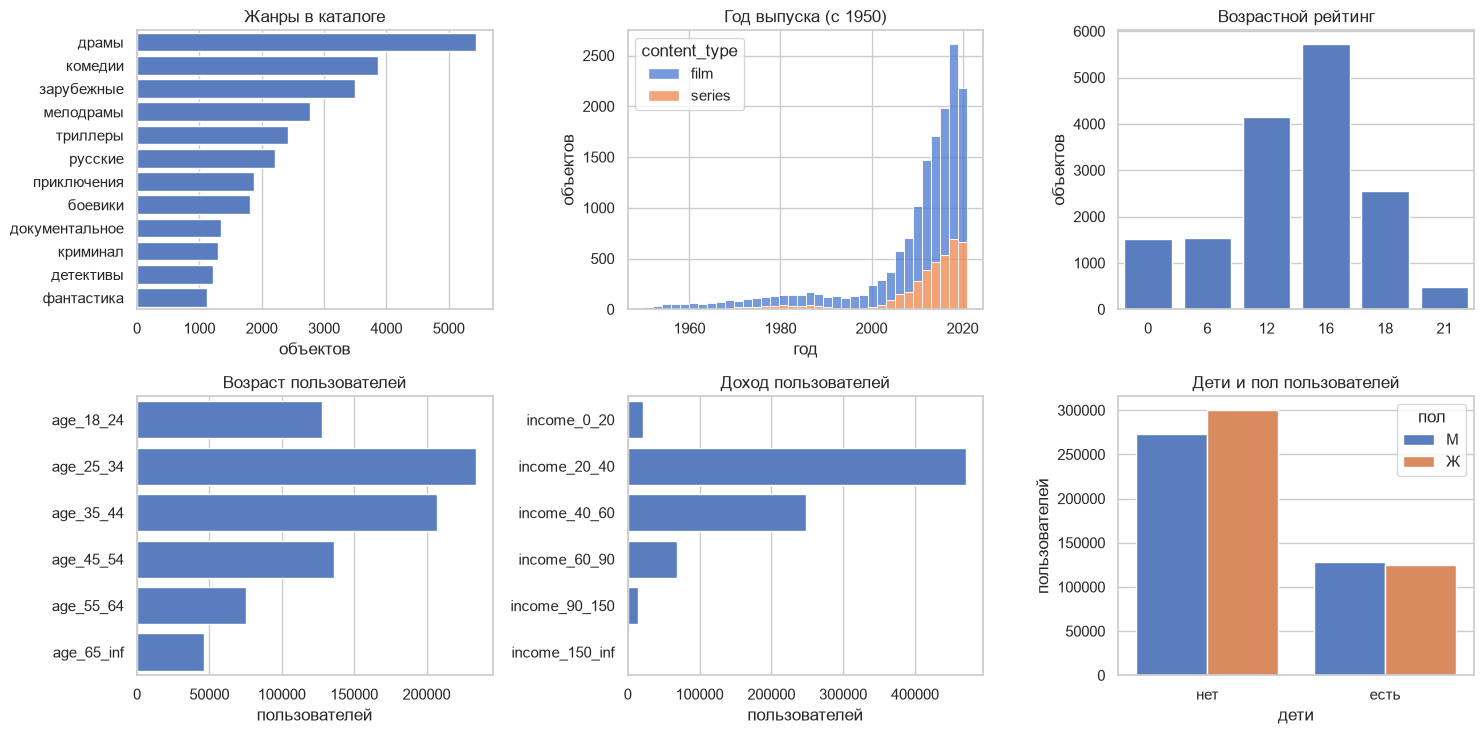

content_type,proportion
str,f64
"""film""",0.751864
"""series""",0.248136


In [8]:
genres = (items.select(pl.col("genres").str.split(", ")).explode("genres")
          .group_by("genres").len().sort("len", descending=True).head(12))
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
sns.barplot(genres.to_pandas(), x="len", y="genres", ax=axes[0, 0])
sns.histplot(items.filter(pl.col("release_year") >= 1950).select("release_year", "content_type").to_pandas(),
             x="release_year", hue="content_type", multiple="stack", bins=36, ax=axes[0, 1])
sns.countplot(items.select(pl.col("age_rating").cast(pl.Int64)).drop_nulls().to_pandas(), x="age_rating", ax=axes[0, 2])
sns.countplot(users.sort("age").to_pandas(), y="age", ax=axes[1, 0])
sns.countplot(users.to_pandas(), y="income", ax=axes[1, 1],
              order=["income_0_20", "income_20_40", "income_40_60", "income_60_90", "income_90_150", "income_150_inf"])
sns.countplot(users.select(pl.col("sex").alias("пол"),
                           pl.col("kids_flg").replace_strict({0: "нет", 1: "есть"}).alias("дети")).to_pandas(),
              x="дети", hue="пол", order=["нет", "есть"], ax=axes[1, 2])
axes[0, 0].set(title="Жанры в каталоге", xlabel="объектов", ylabel="")
axes[0, 1].set(title="Год выпуска (с 1950)", xlabel="год", ylabel="объектов")
axes[0, 2].set(title="Возрастной рейтинг", xlabel="", ylabel="объектов")
axes[1, 0].set(title="Возраст пользователей", xlabel="пользователей", ylabel="")
axes[1, 1].set(title="Доход пользователей", xlabel="пользователей", ylabel="")
axes[1, 2].set(title="Дети и пол пользователей", xlabel="дети", ylabel="пользователей")
plt.tight_layout()
plt.show()

items["content_type"].value_counts(normalize=True, sort=True)

- **Пропуски и дубликаты.** Дубликатов нет: на каждую пару пользователь–объект одна строка. В `interactions` не заполнено меньше 0,02 % значений `watched_pct`.
- **Активность и популярность** распределены с длинным хвостом. У половины пользователей не больше двух просмотров. На 1 % самых популярных объектов приходится 46 % просмотров, на 10 % - 85 %. Матрица заполнена на 0,04 %.
- **Каталог.** Три четверти каталога - фильмы, остальное - сериалы; больше двух третей объектов вышли после 2010 года. Чаще всего встречаются рейтинги 12+ и 16+.
- **Анкеты.** У 218 тыс. пользователей (23 %) анкеты нет. В заполненных анкетах пропусков мало, около 2 %. Мужчин и женщин примерно поровну, дети есть у 30 %.
- **Плохо заполненные поля.** «Для детей» заполнено у 4 % объектов, пропуск считаем как «не для детей». Студии заполнены у 7 %, их не используем.

**Подготовка.**

1. Удаляем строки без `watched_pct`. Их меньше тысячи, а без доли просмотра не всегда определить релевантность и не посчитать таргет модели 4.5.
2. Берем случайные 25 % пользователей (зерно 2021): в полном датасете 5,5 млн взаимодействий, а по условию нужно не больше 2 млн. Отбор по пользователям сохраняет их истории целиком.
3. Повторяем до сходимости фильтр «у пользователя от 5 просмотров, у объекта от 10». С короткой историей пользователя нечего делить по времени, а по редким объектам не оценить сходство.

In [9]:
steps = [("исходные", interactions)]
clean = interactions.drop_nulls("watched_pct")
steps.append(("без пропусков watched_pct", clean))
sample = clean.select("user_id").unique().sort("user_id").sample(fraction=0.25, seed=SEED)
data = clean.join(sample, on="user_id", how="semi")
steps.append(("25% пользователей", data))
while True:
    size = data.height
    data = data.filter(pl.len().over("user_id") >= 5).filter(pl.len().over("item_id") >= 10)
    if data.height == size:
        break
steps.append(("фильтр 5 / 10", data))

pl.DataFrame([{"шаг": name, "взаимодействий": frame.height, "пользователей": frame["user_id"].n_unique(),
               "объектов": frame["item_id"].n_unique(),
               "плотность": frame.height / (frame["user_id"].n_unique() * frame["item_id"].n_unique())}
              for name, frame in steps])

шаг,взаимодействий,пользователей,объектов,плотность
str,i64,i64,i64,f64
"""исходные""",5476251,962179,15706,0.000362
"""без пропусков watched_pct""",5475423,962151,15605,0.000365
"""25% пользователей""",1366655,240537,12256,0.000464
"""фильтр 5 / 10""",1046173,74645,5143,0.002725


In [10]:
data = data.with_columns(
    (pl.col("user_id").rank("dense") - 1).cast(pl.Int64).alias("user_idx"),
    (pl.col("item_id").rank("dense") - 1).cast(pl.Int64).alias("item_idx"),
    ((pl.col("watched_pct") >= 50) | (pl.col("total_dur") >= 1200)).alias("relevant"),
)
n_users, n_items = data["user_idx"].max() + 1, data["item_idx"].max() + 1
shape = (n_users, n_items)

Остаётся 1,05 млн взаимодействий, 74,6 тыс. пользователей и 5,1 тыс. объектов.

## 3. Протокол оценки

Разбиение по времени, неделя на проверку - как в соревновании Kion:

| часть | период |
|---|---|
| train | до 8 августа 2021 |
| validation | 9–15 августа: подбор гиперпараметров на моделях, обученных на train |
| test | 16–22 августа: лучшие модели переобучаются на train + validation |

- **Кого оцениваем.** Пользователей, у которых есть история до начала недели и хотя бы один релевантный просмотр в ней. Новые пользователи без истории в оценку не входят.
- **Кандидаты.** Объекты, встречавшиеся в истории. Новые объекты недели не входят ни в кандидаты, ни в релевантные.
- **Исключение.** Всё, что пользователь уже открывал, из рекомендаций убираю.
- **Одинаково для всех моделей.** Разбиение, пользователи, кандидаты и критерий релевантности общие. Собственный таргет модели 4.5 используется только при обучении и релевантность на validation и test не меняет.
- **Особенность Kion.** На пару пользователь–объект одна строка с датой последнего просмотра, поэтому начатое раньше и досмотренное в тестовую неделю попадает в test.

Метрики при K = 10:
- **MAP@10** - основная, выбрана до подбора. Пользователь видит подборку из 10 позиций и чаще выбирает из первых, поэтому важно и сколько в ней релевантных объектов, и на каких они местах. Это же метрика соревнования Kion;
- **Recall@10** - какую долю релевантного за неделю нашла подборка. Позиции не учитывает, зато показывает полноту: сколько из того, что пользователь действительно посмотрел, мы угадали;
- **HitRate@10** - доля пользователей, которым попался хотя бы один релевантный объект, то есть как часто подборка вообще полезна.

$$\mathrm{AP@10}(u) = \frac{1}{\min(10, |R_u|)}\sum_{k=1}^{10} P@k(u)\,\mathrm{rel}_u(k)$$

$$\mathrm{Recall@10}(u) = \frac{|\mathrm{top10}(u) \cap R_u|}{|R_u|}, \qquad \mathrm{HitRate@10}(u) = \bigl[\mathrm{top10}(u) \cap R_u \neq \varnothing\bigr]$$

$R_u$ - объекты, релевантные для пользователя $u$ на неделе оценки; $\mathrm{rel}_u(k) = 1$, если $k$-й рекомендованный объект релевантен. Метрики усредняются по оцениваемым пользователям.

In [11]:
VAL_START, TEST_START, END = date(2021, 8, 9), date(2021, 8, 16), date(2021, 8, 23)
val = utils.Fold(data, VAL_START, TEST_START, n_users, n_items)
test = utils.Fold(data, TEST_START, END, n_users, n_items)

pl.DataFrame({
    "": ["взаимодействий в истории", "взаимодействий в окне", "оцениваемых пользователей",
         "релевантных пар", "кандидатов"],
    "validation": [val.history.height, val.window.height, len(val.users), val.truth.nnz, int(val.candidates.sum())],
    "test": [test.history.height, test.window.height, len(test.users), test.truth.nnz, int(test.candidates.sum())],
})

,validation,test
str,i64,i64
"""взаимодействий в истории""",894461,969810
"""взаимодействий в окне""",75349,76363
"""оцениваемых пользователей""",16049,16138
"""релевантных пар""",37724,38468
"""кандидатов""",5062,5111


## 4. Модели и подбор гиперпараметров

Все модели - в `models/`, общий код протокола и метрик - в `utils.py`. Гиперпараметры подбираются перебором по сетке на validation; критерий - MAP@10. Сетки указаны у каждой модели.

### 4.1. UserKNN

Сходство пользователей - косинус по бинарной матрице просмотров со сжатием $\beta$:
$$s_{uv} = \frac{|I_u \cap I_v|}{\sqrt{|I_u|\,|I_v|} + \beta}, \qquad \hat r_{ui} = \sum_{v \in N_k(u)} s_{uv}\,x_{vi}$$
$N_k(u)$ - $k$ самых похожих пользователей. Сетка: $k \in \{50, 100, 200, 400\}$, $\beta \in \{0, 10, 50\}$.

In [12]:
knn = utils.grid_search(lambda p, f: UserKNN(**p).fit(f.matrix),
                        {"neighbours": [50, 100, 200, 400], "shrink": [0.0, 10.0, 50.0]}, val)
knn

neighbours,shrink,MAP@10,Recall@10,HitRate@10
i64,f64,f64,f64,f64
200,10.0,0.103944,0.208572,0.325379
400,0.0,0.103893,0.209913,0.325005
200,0.0,0.103659,0.208036,0.323447
400,10.0,0.103462,0.208918,0.325129
200,50.0,0.102834,0.206368,0.323634
400,50.0,0.102768,0.207097,0.323073
100,10.0,0.100854,0.202541,0.317777
100,50.0,0.10046,0.202372,0.317154
100,0.0,0.099251,0.197333,0.309801


### 4.2. iALS

ALS для неявной обратной связи. Предпочтение $p_{ui} = 1$, если пользователь открывал объект, иначе 0; уверенность $c_{ui} = 1 + \alpha$ для наблюдаемых пар и 1 для остальных:
$$\min_{X, Y} \sum_{u, i} c_{ui}\,(p_{ui} - x_u^\top y_i)^2 + \lambda\Bigl(\sum_u \|x_u\|^2 + \sum_i \|y_i\|^2\Bigr)$$
При фиксированном $Y$ вектор пользователя - решение системы $(Y^\top Y + Y^\top (C_u - I) Y + \lambda I)\,x_u = Y^\top C_u\,p_u$. Решаем её тремя шагами метода сопряжённых градиентов сразу для всех пользователей, начиная с решения прошлой итерации. Для $Y$ - симметрично; 10 итераций. Сетка: факторов $\{64, 128\}$, $\lambda \in \{100, 300, 1000\}$, $\alpha \in \{5, 20, 50\}$.

In [13]:
def fit_ials(params, fold):
    users_, items_ = fold.arrays("user_idx", "item_idx")
    return ImplicitALS(**params, seed=SEED).fit(users_, items_, shape)


als_grid = {"factors": [64, 128], "regularization": [100.0, 300.0, 1000.0], "alpha": [5.0, 20.0, 50.0]}
als = utils.grid_search(fit_ials, als_grid, val)
als.head(8)

factors,regularization,alpha,MAP@10,Recall@10,HitRate@10
i64,f64,f64,f64,f64,f64
64,300.0,5.0,0.095092,0.190765,0.29871
128,300.0,5.0,0.094847,0.190794,0.299146
128,1000.0,50.0,0.094438,0.193503,0.305627
64,1000.0,50.0,0.093945,0.193339,0.305003
128,300.0,20.0,0.093427,0.196498,0.311172
128,1000.0,20.0,0.093133,0.185507,0.287495
64,1000.0,20.0,0.092665,0.185071,0.286809
64,300.0,20.0,0.089207,0.189125,0.302137


### 4.3. EASE

Линейная модель «объект из объектов»:
$$\min_B \|X - XB\|_F^2 + \lambda \|B\|_F^2, \quad \mathrm{diag}(B) = 0 \;\Rightarrow\; P = (X^\top X + \lambda I)^{-1},\; B_{ij} = -\frac{P_{ij}}{P_{jj}}$$
Обращение - через разложение Холецкого. Сетка: $\lambda \in \{50, 100, 200, 500, 1000, 2000\}$.

In [14]:
ease = utils.grid_search(lambda p, f: EASE(**p).fit(f.matrix), {"l2": [50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0]}, val)
ease

l2,MAP@10,Recall@10,HitRate@10
f64,f64,f64,f64
500.0,0.102856,0.210085,0.330799
200.0,0.102743,0.209438,0.330114
100.0,0.10272,0.207299,0.328182
1000.0,0.102563,0.209535,0.33055
50.0,0.10206,0.206067,0.326189
2000.0,0.101966,0.208779,0.327871


### 4.4. Факторизационная машина

$$\hat y(x) = w_0 + \sum_j w_j x_j + \sum_{j < l} \langle v_j, v_l\rangle\, x_j x_l$$

$x$ - признаки пары пользователь–объект. Берем только то, что известно в момент рекомендации: анкету пользователя и карточку объекта из каталога. Статистик, посчитанных по просмотрам, среди признаков нет.
- **пользователь:** ID, возраст, доход, пол, дети. Если анкеты нет, это отдельное значение «unknown»;
- **объект:** ID, тип (фильм или сериал), жанры (с весами $1/n$), страны (10 самых частых, остальные - «другие»), десятилетие выпуска, возрастной рейтинг, пометка «для детей».

Признаки объекта описывают, что это за контент, анкета - кто его смотрит, а FM учитывает их попарные взаимодействия: семьи с детьми смотрят мультфильмы и контент «для детей», разные возрастные группы - разные жанры и рейтинги. Пользователям и объектам с короткой историей эти признаки дополняют ID. Названия, описания, актёров и режиссёров не берем: для 5 тыс. объектов это слишком разреженные признаки.

Обучение - логистическая функция потерь: просмотренная пара - класс 1, на неё 4 случайных объекта-кандидата - класс 0. Оптимизатор AdamW, батч 8192. Для ранжирования член пары раскладывается на «пользователь x объект» и собственный член объекта, поэтому все объекты оцениваются одним умножением матриц. Сетка: размерность $\{32, 64\}$, шаг $\{0.003, 0.01\}$, эпох $\{2, 4\}$.

In [15]:
def one_hot(values):
    categories, codes = np.unique(np.asarray(values, dtype=str), return_inverse=True)
    return sp.csr_matrix((np.ones(len(codes), dtype=np.float32), (np.arange(len(codes)), codes)),
                         shape=(len(codes), len(categories)))


def multi_hot(rows):
    vocabulary = {value: j for j, value in enumerate(sorted({v for row in rows for v in row}))}
    entries = [(i, vocabulary[v], 1.0 / len(row)) for i, row in enumerate(rows) for v in row]
    r, c, w = zip(*entries)
    return sp.csr_matrix((w, (r, c)), shape=(len(rows), len(vocabulary)), dtype=np.float32)


user_table = (data.select("user_idx", "user_id").unique().sort("user_idx")
              .join(users, on="user_id", how="left")
              .with_columns(pl.col("age", "income", "sex").fill_null("unknown"),
                            pl.col("kids_flg").cast(pl.String).fill_null("unknown")))
user_x = sp.hstack([sp.identity(n_users, format="csr", dtype=np.float32)]
                   + [one_hot(user_table[c].to_numpy()) for c in ("age", "income", "sex", "kids_flg")]).tocsr()

item_table = data.select("item_idx", "item_id").unique().sort("item_idx").join(items, on="item_id", how="left")
top_countries = (item_table.select(pl.col("countries").str.split(", ")).explode("countries")
                 .group_by("countries").len().sort("len", descending=True).head(10)["countries"].to_list())
genre_lists = [g.split(", ") if g else ["unknown"] for g in item_table["genres"].fill_null("").to_list()]
country_lists = [[c if c in top_countries else "другие" for c in s.split(", ")] if s else ["unknown"]
                 for s in item_table["countries"].fill_null("").to_list()]
decade = item_table.select((pl.col("release_year") // 10 * 10).cast(pl.Int64).cast(pl.String).fill_null("unknown"))
item_x = sp.hstack([
    sp.identity(n_items, format="csr", dtype=np.float32),
    one_hot(item_table["content_type"].to_numpy()),
    multi_hot(genre_lists),
    multi_hot(country_lists),
    one_hot(decade.to_series().to_numpy()),
    one_hot(item_table["age_rating"].fill_null(-1).cast(pl.String).to_numpy()),
    one_hot(item_table["for_kids"].fill_null(0).cast(pl.String).to_numpy()),
]).tocsr()
pl.DataFrame({"": ["пользователь", "объект"], "ID": [n_users, n_items],
              "признаков кроме ID": [user_x.shape[1] - n_users, item_x.shape[1] - n_items]})

,ID,признаков кроме ID
str,i64,i64
"""пользователь""",74645,20
"""объект""",5143,95


In [16]:
def fit_fm(params, fold):
    users_, items_ = fold.arrays("user_idx", "item_idx")
    return FactorizationMachine(user_x, item_x, **params, seed=SEED).fit(users_, items_, fold.candidates)


fm = utils.grid_search(fit_fm, {"dim": [32, 64], "lr": [0.003, 0.01], "epochs": [2, 4]}, val)
fm

dim,lr,epochs,MAP@10,Recall@10,HitRate@10
i64,f64,i64,f64,f64,f64
32,0.003,2,0.093822,0.186179,0.293352
64,0.003,2,0.092119,0.18464,0.293414
32,0.003,4,0.089228,0.181868,0.287058
64,0.003,4,0.086509,0.178863,0.284192
64,0.01,2,0.084844,0.181225,0.290049
32,0.01,2,0.084799,0.181552,0.288118
32,0.01,4,0.080921,0.171109,0.276092
64,0.01,4,0.078791,0.170616,0.277027


### 4.5. iALS с собственным целевым сигналом

В базовом iALS любое открытие - предпочтение $p_{ui} = 1$, и старый просмотр весит так же, как вчерашний. Но 12 % просмотров короче минуты, а смотрят в Kion то, что вышло недавно, - интерес смещается со временем. Заменяем бинарный таргет на оценку текущего интереса:

$$p_{ui} = \Bigl(\tfrac12 + \tfrac12\, d_{ui}\Bigr)\, e^{-\Delta_{ui}/\tau}, \qquad d_{ui} = \min\Bigl(1,\ \max\Bigl(\frac{\text{watched\_pct}_{ui}}{50},\ \frac{\text{total\_dur}_{ui}}{1200}\Bigr)\Bigr)$$

- $d_{ui}$ - глубина просмотра относительно порога релевантности: 1 у досмотренного до половины или просмотренного 20 минут, около 0 у брошенного сразу.
- Половина таргета - за сам выбор объекта: открыл, значит был интерес, даже если не досмотрел.
- $\Delta_{ui}$ - сколько дней прошло от просмотра до момента рекомендации; $\tau = 60$ дней, то есть вклад просмотра двухмесячной давности падает в $e$ раз.

Уверенность $c_{ui} = 1 + \alpha$ та же, что в базовом iALS - отличается только целевой сигнал. Сетка и протокол те же, что в 4.2, а релевантность на validation и test определяется общим правилом из раздела 1: таргет меняет только обучение. Поэтому сравнение с базовым iALS честное.

In [17]:
def fit_custom(params, fold):
    users_, items_, pct, dur = fold.arrays("user_idx", "item_idx", "watched_pct", "total_dur")
    return EngagementALS(**params, seed=SEED).fit(users_, items_, shape, pct, dur, fold.age_days())


custom = utils.grid_search(fit_custom, als_grid, val)
custom.head(8)

factors,regularization,alpha,MAP@10,Recall@10,HitRate@10
i64,f64,f64,f64,f64,f64
128,300.0,50.0,0.106294,0.215566,0.336906
128,300.0,20.0,0.105642,0.214283,0.336781
64,300.0,20.0,0.105369,0.213985,0.335846
128,100.0,5.0,0.101789,0.20989,0.331734
64,300.0,50.0,0.101183,0.208782,0.327933
64,100.0,5.0,0.100893,0.209008,0.330363
128,1000.0,50.0,0.098349,0.204315,0.316967
64,1000.0,50.0,0.098199,0.20383,0.316032


## 5. Сравнение на test

Модели с лучшими на validation параметрами переобучаю на train + validation и один раз оцениваю на тестовой неделе. В общей таблице - метрики на test, MAP@10 на validation и выбранные гиперпараметры.

In [18]:
searches = {"UserKNN": knn, "iALS": als, "EASE": ease, "FM": fm, "iALS + свой таргет": custom}
fits = {
    "UserKNN": lambda p, f: UserKNN(**p).fit(f.matrix),
    "iALS": fit_ials,
    "EASE": lambda p, f: EASE(**p).fit(f.matrix),
    "FM": fit_fm,
    "iALS + свой таргет": fit_custom,
}
rows = []
for name, grid in searches.items():
    best = grid.row(0, named=True)
    params = {k: v for k, v in best.items() if k not in ("MAP@10", "Recall@10", "HitRate@10")}
    rows.append({"модель": name, **utils.evaluate(fits[name](params, test), test),
                 "MAP@10 на validation": best["MAP@10"],
                 "гиперпараметры": ", ".join(f"{k}={v:g}" for k, v in params.items())})
results = pl.DataFrame(rows).sort("MAP@10", descending=True)
results

модель,MAP@10,Recall@10,HitRate@10,MAP@10 на validation,гиперпараметры
str,f64,f64,f64,f64,str
"""EASE""",0.097878,0.204833,0.322531,0.102856,"""l2=500"""
"""iALS + свой таргет""",0.097461,0.206179,0.326744,0.106294,"""factors=128, regularization=300, alpha=50"""
"""UserKNN""",0.097077,0.201553,0.315219,0.103944,"""neighbours=200, shrink=10"""
"""iALS""",0.090611,0.184836,0.293407,0.095092,"""factors=64, regularization=300, alpha=5"""
"""FM""",0.087953,0.181479,0.285475,0.093822,"""dim=32, lr=0.003, epochs=2"""


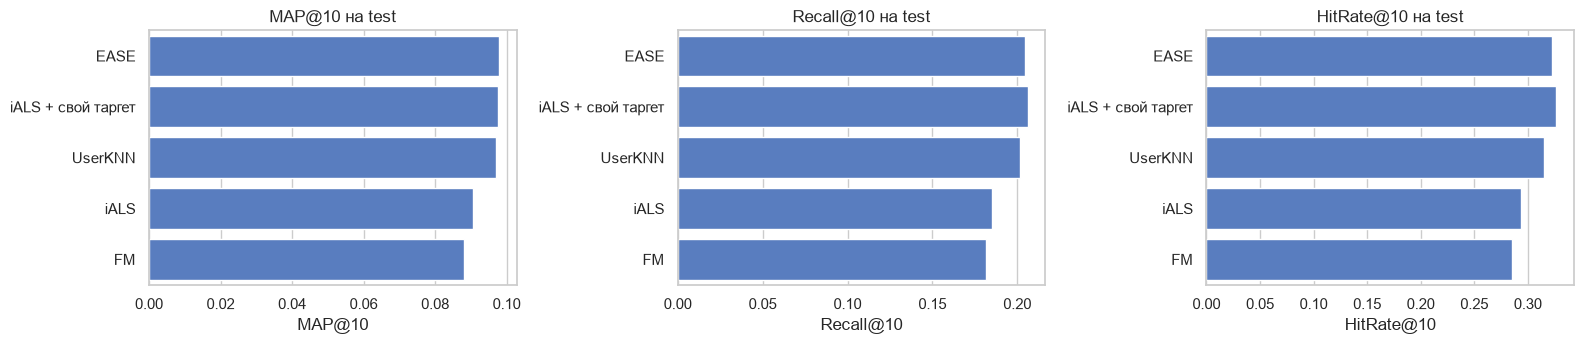

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, metric in zip(axes, ("MAP@10", "Recall@10", "HitRate@10")):
    sns.barplot(results.to_pandas(), x=metric, y="модель", ax=ax)
    ax.set(title=f"{metric} на test", ylabel="")
plt.tight_layout()
plt.show()

## 6. Выводы

**Лучшие модели на test** - EASE (MAP@10 = 0,098), iALS со своим таргетом (0,097) и UserKNN (0,097). Разница между ними меньше 0,001, фактически не имеет значения. По Recall@10 и HitRate@10 немного впереди iALS со своим таргетом: 0,206 и 0,327 против 0,205 и 0,323 у EASE.
**Отстают** базовый iALS (0,091) и FM (0,088).

**Лучшие настройки:**
  - EASE - λ = 500, но в диапазоне 50–2000 качество почти не меняется;
  - UserKNN - 200 соседей, сжатие β = 10;
  - iALS - сильная регуляризация, λ = 300; со своим таргетом - та же λ, но 128 факторов и α = 50;
  - FM - 2 эпохи с шагом 0,003, дальше она переобучается.

**Свой целевой сигнал** (досмотр и затухание по давности) при той же сетке и протоколе поднял MAP@10 iALS с 0,091 до 0,097, Recall@10 - с 0,185 до 0,206, HitRate@10 - с 0,293 до 0,327; на validation MAP@10 вырос с 0,095 до 0,106. С ним iALS переходит с четвёртого места в группу лидеров.

**Метаданные** не вывели FM вперёд: с анкетой и признаками каталога она слабее всех моделей, обученных только на истории просмотров.

**Ограничения:**
  - в выборке 25 % пользователей, и только с историей от 5 просмотров; фильтр 5 / 10 считал просмотры за весь период, включая test;
  - новые пользователи и объекты в оценку не входят;
  - разбиение одно, поэтому разница в тысячные доли MAP@10 между лучшими моделями ненадёжна;
  - в Kion для каждой пары хранится только дата последнего просмотра;